# Response maps in $(\eta, \phi)$: uncertainty-aware regression in 2D

We regress a detector response $y$ (think: an unbinned scale factor) over the $(\eta,\phi)$ plane. Same machinery as the 1D warm-up — the target is still one scalar, so *nothing* in the toolbox changes — but the input is now a plane.

1. **Uncertainty becomes a map.** Aleatoric, epistemic, coverage: each is a heatmap over the detector, and the epistemic map should reproduce *the shape of the missing data*.
2. **Conditional coverage becomes visible.** Marginal conformal gives a coverage *map* that averages to 90% while being red in specific places; 

**The dataset leads a double life**: the companion notebook reuses the *identical* generator for density estimation (the acceptance $p(\eta,\phi)$ and the joint $p(y,\eta,\phi)$). Design choices below (the prescaled sector, analytic everything) exist for that second life.

What is in the toy — all analytic, so every claim is checkable:
- response surface $\mu(\eta,\phi)$: crack rings at $|\eta|=1.5$, a $\cos\phi$ misalignment ripple, one localized bad patch;
- aleatoric width $\sigma(\eta)$ growing toward high $|\eta|$, plus a low-side exponential tail with probability $p_t(\eta)$ — the conditional is a Gaussian + **exponentially-modified-Gaussian** mixture in closed form;
- acceptance: event rate falling with $|\eta|$, a $\cos 2\phi$ modulation, and one $\phi$ **sector at 4% efficiency** ("under repair" — prescaled, not dead, on purpose: the density-estimation day needs strictly positive density).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from math import erfc

rng = np.random.default_rng(0); torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (7, 3); plt.rcParams["figure.dpi"] = 110
_erfc = np.vectorize(erfc)

# ---------- SHARED GENERATOR (identical cell in the density-estimation notebook) ----------
ETA_MAX, SECTOR, SECTOR_EFF, TAU = 2.5, (0.6, 1.2), 0.04, 0.06

def mu_true(eta, phi):
    crack = -0.06 * np.exp(-0.5 * ((np.abs(eta) - 1.5) / 0.10) ** 2)   # crack rings at |eta|=1.5
    align =  0.012 * np.cos(phi)                                        # cartoon misalignment
    patch = -0.08 * np.exp(-0.5 * (((eta - 0.5) ** 2 + (phi + 2.0) ** 2) / 0.25 ** 2))  # bad supermodule
    return 1.0 + crack + align + patch

def sigma_true(eta):  return 0.02 + 0.03 * (np.abs(eta) / ETA_MAX) ** 2
def ptail_true(eta):  return 0.05 + 0.15 * (np.abs(eta) / ETA_MAX) ** 2

def p_y_cond(y, eta, phi):
    """ANALYTIC p(y|eta,phi): Gaussian core + EMG low-side tail (exp. modified Gaussian)."""
    mu, sig, pt = mu_true(eta, phi), sigma_true(eta), ptail_true(eta)
    lam = 1.0 / TAU
    gauss = np.exp(-0.5 * ((y - mu) / sig) ** 2) / (sig * np.sqrt(2 * np.pi))
    z = ((y - mu) / sig + lam * sig) / np.sqrt(2)
    emg = 0.5 * lam * np.exp(np.clip(lam * (y - mu) + 0.5 * (lam * sig) ** 2, -700, 700)) * _erfc(z)
    return (1 - pt) * gauss + pt * emg

def p_eta_un(eta):    return np.exp(-0.5 * (eta / 1.4) ** 2)
def sector_eff(phi):  return np.where((phi > SECTOR[0]) & (phi < SECTOR[1]), SECTOR_EFF, 1.0)
def p_phi_un(phi):    return (1 + 0.25 * np.cos(2 * phi)) * sector_eff(phi)
_eg = np.linspace(-ETA_MAX, ETA_MAX, 4001); _pg = np.linspace(-np.pi, np.pi, 4001)
Z_ETA = np.trapezoid(p_eta_un(_eg), _eg); Z_PHI = np.trapezoid(p_phi_un(_pg), _pg)

def log_p_pos(eta, phi):
    """ANALYTIC acceptance density p(eta, phi) (separable)."""
    return np.log(p_eta_un(eta) / Z_ETA) + np.log(p_phi_un(phi) / Z_PHI)

def simulate(n, rng):
    eta = np.empty(0)
    while eta.size < n:
        cand = rng.normal(0, 1.4, 2 * n); eta = np.concatenate([eta, cand[np.abs(cand) < ETA_MAX]])
    eta = eta[:n]
    phi = np.empty(0)
    while phi.size < n:
        cand = rng.uniform(-np.pi, np.pi, 3 * n)
        phi = np.concatenate([phi, cand[rng.random(cand.size) * 1.25 < p_phi_un(cand)]])
    phi = phi[:n]
    mu, sig, pt = mu_true(eta, phi), sigma_true(eta), ptail_true(eta)
    y = mu + sig * rng.standard_normal(n) - np.where(rng.random(n) < pt, rng.exponential(TAU, n), 0.0)
    return dict(eta=eta.astype(np.float32), phi=phi.astype(np.float32), y=y.astype(np.float32))

### Generator self-check 
Before fitting anything: does the analytic conditional actually describe the Monte Carlo? Two points, one central and one at high $|\eta|$ where the tail is strong.

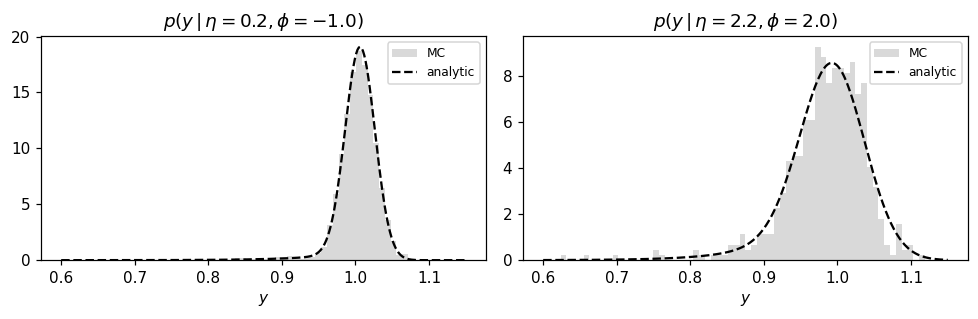

In [2]:
big = simulate(1_500_000, rng)
CHECKPTS = [(0.2, -1.0), (2.2, 2.0)]
yg = np.linspace(0.6, 1.15, 300)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for a, (e0, f0) in zip(ax, CHECKPTS):
    m = (np.abs(big["eta"] - e0) < 0.06) & (np.abs(big["phi"] - f0) < 0.12)
    a.hist(big["y"][m], bins=70, range=(0.6, 1.15), density=True, color="0.85", label="MC")
    a.plot(yg, p_y_cond(yg, e0, f0), "k--", label="analytic")
    a.set(xlabel="$y$", title=f"$p(y\\,|\\,\\eta={e0}, \\phi={f0})$"); a.legend(fontsize=8)
plt.tight_layout()

## 1. Look at the plane

Training statistics are realistic-ish: 60k labelled events. The scatter shows the sector hole and the $|\eta|$ falloff; the truth maps show what the network must find.

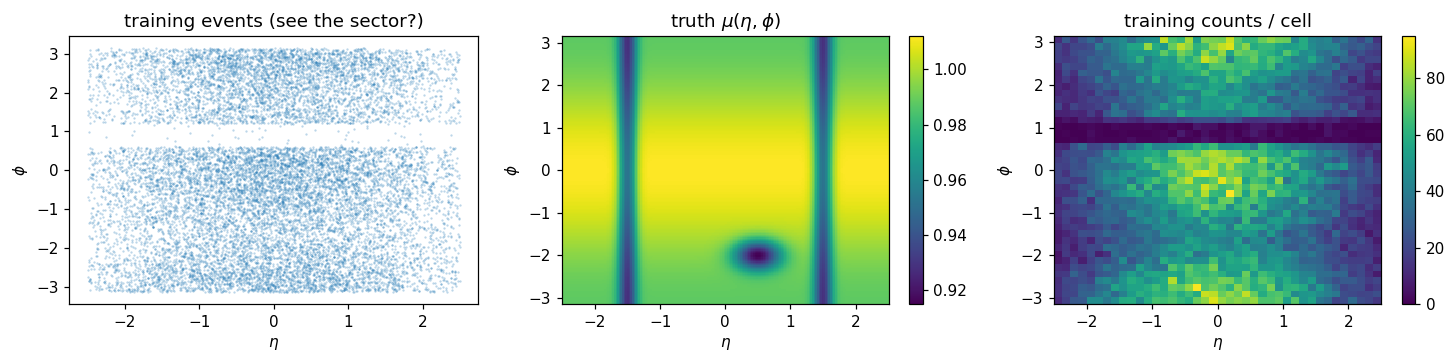

In [3]:
train_d = simulate(60_000, rng)
cal_d   = simulate(40_000, rng)
test_d  = simulate(150_000, rng)

def stat_map(eta, phi, vals=None, bins=40, reduce="mean"):
    H, xe, ye = np.histogram2d(eta, phi, bins=bins, range=[[-ETA_MAX, ETA_MAX], [-np.pi, np.pi]])
    if vals is None: return H, xe, ye
    W, _, _ = np.histogram2d(eta, phi, bins=bins, range=[[-ETA_MAX, ETA_MAX], [-np.pi, np.pi]], weights=vals)
    with np.errstate(invalid="ignore"): out = W / H
    return out, xe, ye

def show(ax, Mp, xe, ye, title, **kw):
    im = ax.pcolormesh(xe, ye, Mp.T, **kw)
    plt.colorbar(im, ax=ax); ax.set(title=title, xlabel=r"$\eta$", ylabel=r"$\phi$")

eg = np.linspace(-ETA_MAX, ETA_MAX, 200); fg = np.linspace(-np.pi, np.pi, 200)
E, F = np.meshgrid(eg, fg, indexing="ij")

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.4))
ax[0].plot(train_d["eta"][:15000], train_d["phi"][:15000], ".", ms=1, alpha=0.3)
ax[0].set(title="training events (see the sector?)", xlabel=r"$\eta$", ylabel=r"$\phi$")
show(ax[1], mu_true(E, F), eg, fg, r"truth $\mu(\eta,\phi)$")
H, xe, ye = stat_map(train_d["eta"], train_d["phi"])
show(ax[2], H, xe, ye, "training counts / cell")
plt.tight_layout()

## 2. Toolbox and features

Toolbox unchanged from the previous notebooks. One 2D-specific choice worth a sentence: $\phi$ is **periodic**, so we feed $(\eta, \cos\phi, \sin\phi)$ — a network fed raw $\phi$ invents a seam at $\pm\pi$. (Ablation exercise at the end; the density notebook meets the same issue from the flow side.)

In [4]:
def pit_values(y, samples): return (samples < y[:, None]).mean(axis=1)

def central_coverage(y, samples, level):
    a = (1 - level) / 2
    lo, hi = np.quantile(samples, a, axis=1), np.quantile(samples, 1 - a, axis=1)
    return np.mean((y >= lo) & (y <= hi)), np.mean(hi - lo)

def crps_from_samples(y, samples):
    t1 = np.abs(samples - y[:, None]).mean(axis=1)
    s = np.sort(samples, axis=1); S = samples.shape[1]; k = np.arange(1, S + 1)
    return float((t1 - 0.5 * (2.0/S**2) * ((2*k - S - 1) * s).sum(axis=1)).mean())

def scoreboard(y, methods, levels=(0.68, 0.95)):
    print(f"{'method':<18}{'CRPS':>9}" + "".join(f"{'cov'+str(int(l*100)):>8}{'width'+str(int(l*100)):>9}" for l in levels))
    for name, s in methods.items():
        row = f"{name:<18}{crps_from_samples(y, s):>9.5f}"
        for l in levels:
            c, w = central_coverage(y, s, l); row += f"{c:>8.3f}{w:>9.4f}"
        print(row)

def features(d): return np.stack([d["eta"], np.cos(d["phi"]), np.sin(d["phi"])], 1).astype(np.float32)

class Standardizer:
    def fit(self, x): self.m, self.s = x.mean(0), x.std(0); return self
    def __call__(self, x): return (x - self.m) / self.s

std = Standardizer().fit(features(train_d))
x_tr, y_tr = std(features(train_d)), train_d["y"]
x_cal, y_cal = std(features(cal_d)), cal_d["y"]
x_te, y_te = std(features(test_d)), test_d["y"]
in_sector = (test_d["phi"] > SECTOR[0]) & (test_d["phi"] < SECTOR[1])
METHODS = {}

## 3. Heteroscedastic head  — and the first map payoff

Train $(\mu(x), \sigma(x))$ with $\beta$-NLL as before. The map payoff: predicted $\mu$ next to the truth (does it find the crack, the ripple, the patch — even *inside* the sector, by interpolation?), and learned $\sigma$ next to the analytic $\sigma(\eta)$.

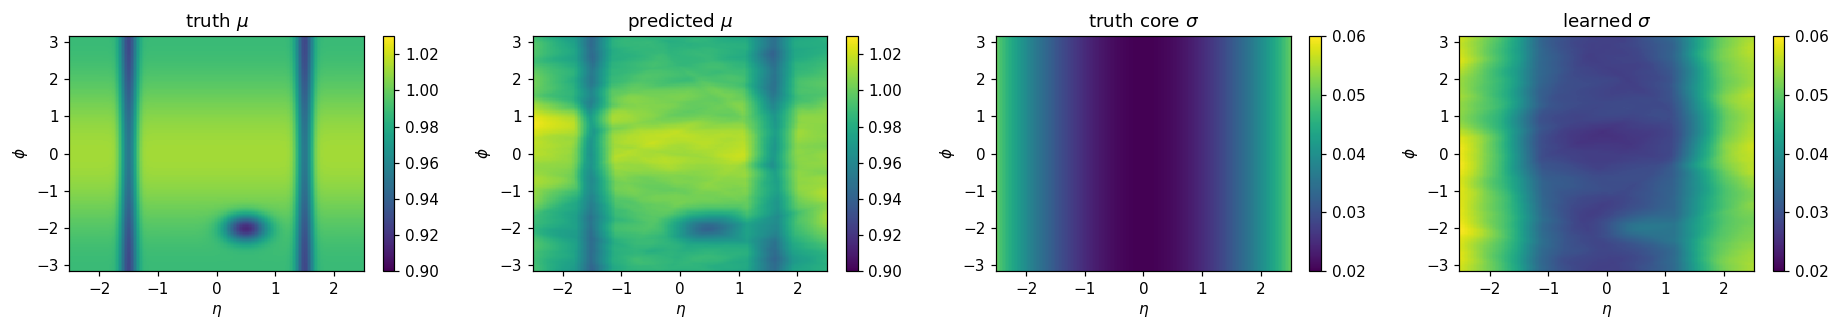

In [5]:
def mlp(n_in, n_out, hidden=96, depth=3, dropout=0.0):
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), nn.ReLU()]
        if dropout > 0: layers += [nn.Dropout(dropout)]
        d = hidden
    return nn.Sequential(*(layers + [nn.Linear(d, n_out)]))

def train(model, loss_fn, x, y, epochs=40, lr=1e-3, batch=512, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    x, y = torch.as_tensor(x), torch.as_tensor(y)
    for ep in range(epochs):
        perm = torch.randperm(x.shape[0])
        for i in range(0, x.shape[0], batch):
            idx = perm[i:i + batch]
            opt.zero_grad(); loss_fn(model(x[idx]), y[idx]).backward(); opt.step()
    return model

def gauss_nll(out, y, beta=0.5):
    mu, log_s = out[:, 0], out[:, 1]
    sig = nn.functional.softplus(log_s) + 1e-4
    nll = 0.5 * ((y - mu) / sig) ** 2 + torch.log(sig)
    if beta > 0: nll = nll * sig.detach() ** (2 * beta)
    return nll.mean()

def hetero_predict(model, x):
    with torch.no_grad(): out = model(torch.as_tensor(x))
    return out[:, 0].numpy(), nn.functional.softplus(out[:, 1]).numpy() + 1e-4

def gaussian_samples(mu, sig, S=400):
    return mu[:, None] + sig[:, None] * rng.standard_normal((mu.size, S))

het = train(mlp(3, 2), gauss_nll, x_tr, y_tr)
METHODS["heteroscedastic"] = gaussian_samples(*hetero_predict(het, x_te))

xg_grid = std(np.stack([E.ravel(), np.cos(F.ravel()), np.sin(F.ravel())], 1).astype(np.float32))
mu_g, sig_g = hetero_predict(het, xg_grid)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.1))
show(ax[0], mu_true(E, F), eg, fg, r"truth $\mu$", vmin=0.9, vmax=1.03)
show(ax[1], mu_g.reshape(E.shape), eg, fg, r"predicted $\mu$", vmin=0.9, vmax=1.03)
show(ax[2], (sigma_true(E) * np.ones_like(F)), eg, fg, r"truth core $\sigma$", vmin=0.02, vmax=0.06)
show(ax[3], sig_g.reshape(E.shape), eg, fg, r"learned $\sigma$", vmin=0.02, vmax=0.06)
plt.tight_layout()

Read the maps: the crack rings and the ripple are found; the bad patch too — check whether its edge is sharp or smoothed (the network's inductive bias at work). The learned $\sigma$ exceeds the truth-core $\sigma$ at high $|\eta|$: the Gaussian inflating to absorb the EMG tail, exactly the 1D story, now with geography. Inside the sector the prediction is an *interpolation* — plausible-looking, and with no honest error bar yet.

**EXERCISE:** plot the PIT histogram in three regions (central, high $|\eta|$, the bad patch) — where is the Gaussian family wrong vs merely miscalibrated?

## 4. Epistemic map: the ensemble

The 2D money plot: the epistemic uncertainty (the std of $\mu_m$ over the ensemble members) as a map in $(\eta,\phi)$, next to the map of the training density. Two regions of the plane have little training data, for two different reasons:

- the **edges** at high $|\eta|$, where the event rate falls off;
- the **sector**: the band $0.6 < \phi < 1.2$ (`SECTOR`), at all $\eta$, where only 4% of the events are kept (`SECTOR_EFF`) — a part of the detector "under repair". The sector removes *data*, not *physics*: the true response $\mu(\eta,\phi)$ has no special feature there and continues smoothly across it.

Before running the cell, predict which of the two should light up. Then look carefully, because the answer is more interesting than "wherever data is scarce":

- the high-$|\eta|$ **edges light up strongly**: there is little data *and* the response surface is steep there, so the members extrapolate in different ways;
- the **sector lights up only faintly**, although it has 25 times less data than its surroundings. Why? The surface is smooth in $\phi$ and the sector is narrow ($\Delta\phi = 0.6$), with full data on both sides. The five independent networks therefore all interpolate across it in the *same* way — they agree, so their spread is small.

The lesson: **epistemic uncertainty measures how ambiguous the extension into the empty region is under your model class, not the raw data density.** Small spread in the sector means "all the members make the same assumption (smoothness)", not "the prediction is right". Here the assumption happens to be true, so the agreement is earned. When it is false, the agreement is dangerous: the members agree *and* are all wrong together.

**EXERCISE 1 — make the assumption false.** The **bad patch** is a different object from the sector: a localized dip of the response (a "bad supermodule") at $\eta = 0.5$, $\phi = -2.0$, in a region with full data, so the networks do find it. Move it inside the sector: in `mu_true`, change `(phi + 2.0)` to `(phi - 0.9)`, and re-run. Now barely any training event sees the patch, every member interpolates smoothly past it, the epistemic map stays dark there — and the predictions are silently wrong. This is an "unknown unknown": **ensembles bound disagreement, not error.**

**EXERCISE 2 — make the gap wide.** Put the patch back and widen the sector to $\Delta\phi \sim 2$, for example `SECTOR = (0.0, 2.0)`. The data on the two sides no longer pin down the interpolation, the members start to disagree, and the honest widening appears in the map.

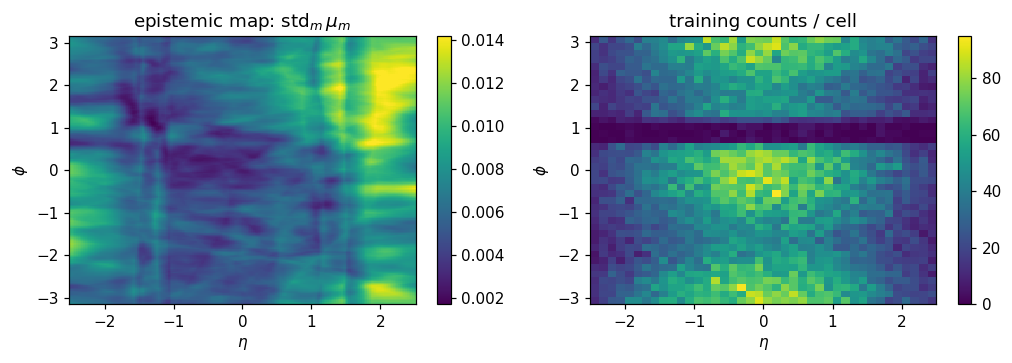

In [6]:
# === SOLUTION ===
members = [train(mlp(3, 2), gauss_nll, x_tr, y_tr, seed=m) for m in range(5)]
mus_te, sigs_te = zip(*[hetero_predict(m, x_te) for m in members])
mus_te, sigs_te = np.stack(mus_te), np.stack(sigs_te)
METHODS["deep ensemble"] = np.concatenate(
    [gaussian_samples(mus_te[m], sigs_te[m], S=80) for m in range(5)], axis=1)

mus_grid = np.stack([hetero_predict(m, xg_grid)[0] for m in members])
epi_map = mus_grid.std(0).reshape(E.shape)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
show(ax[0], epi_map, eg, fg, "epistemic map: std$_m\\,\\mu_m$", vmax=np.quantile(epi_map, 0.995))
H, xe, ye = stat_map(train_d["eta"], train_d["phi"])
show(ax[1], H, xe, ye, "training counts / cell")
plt.tight_layout()

## 5. Numbers, then the coverage MAP

Scoreboard overall and in the sector. Then the new diagnostic this notebook exists for: **empirical coverage per cell of the plane**, using marginal split conformal on the heteroscedastic net (normalised-residual score). The marginal number will be fine; the map will not be uniform — the crack, the sector and high $|\eta|$ under- or over-cover while the bulk compensates. Marginal $\ne$ conditional, as a picture.

--- full plane ---
method                 CRPS   cov68  width68   cov95  width95


heteroscedastic     0.01866   0.757   0.0689   0.959   0.1349


deep ensemble       0.01899   0.757   0.0695   0.957   0.1364

--- sector only ---
method                 CRPS   cov68  width68   cov95  width95
heteroscedastic     0.01836   0.761   0.0671   0.957   0.1310
deep ensemble       0.01850   0.778   0.0702   0.962   0.1378



marginal conformal: q=1.441 (nominal 1.645), overall coverage 0.900 (target 0.9)


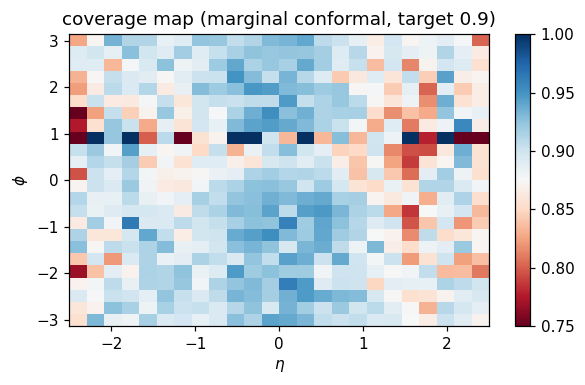

In [7]:
print("--- full plane ---"); scoreboard(y_te, METHODS)
print("\n--- sector only ---")
scoreboard(y_te[in_sector], {k: v[in_sector] for k, v in METHODS.items()})

alpha = 0.1
mu_c, sig_c = hetero_predict(het, x_cal)
qhat = np.sort(np.abs(y_cal - mu_c) / sig_c)[int(np.ceil((len(y_cal)+1)*(1-alpha))) - 1]
mu_t, sig_t = hetero_predict(het, x_te)
inside = (np.abs(y_te - mu_t) / sig_t) <= qhat
print(f"\nmarginal conformal: q={qhat:.3f} (nominal 1.645), overall coverage {inside.mean():.3f} (target {1-alpha})")

cov_map, xe, ye = stat_map(test_d["eta"], test_d["phi"], inside.astype(float), bins=24)
fig, ax = plt.subplots(figsize=(5.6, 3.6))
show(ax, cov_map, xe, ye, f"coverage map (marginal conformal, target {1-alpha})",
     cmap="RdBu", vmin=0.75, vmax=1.0)
plt.tight_layout()

## 7. Where to go from here

- **PIT map exercise:** map of the *mean* PIT per cell — bias shows as spatial structure the way miscalibration showed in the coverage map.
- **BBB / SGLD:** drop in the implementations from the calorimeter notebook unchanged; compare their epistemic maps to the ensemble's.
- **Exact GP reference:** on a 500-event subsample the 2D GP posterior-variance surface is computable (warm-up notebook code, 2D kernel) — the reference the ensemble map should resemble.
- **Ablation:** feed raw $\phi$ instead of $(\cos\phi, \sin\phi)$ and find the seam at $\pm\pi$ in the $\mu$ map.
- **The double life:** the companion notebook fits this generator's *densities*: the acceptance $p(\eta,\phi)$ your epistemic map was secretly tracking, and the joint $p(y,\eta,\phi)$ whose slices are the analytic conditionals we validated in Part 0.